# PredictGuard AI — Phase 2: Regression Track
###Linear, Polynomial & Multivariate Regression

Dataset: **AI4I 2020 Predictive Maintenance Dataset**
Target: **Tool wear [min]** (continuous) — used as a degradation/RUL-style proxy.


## Step 1 — Get the AI4I 2020 dataset

Two options below — try Option A first (direct UCI download), fall back to Option B (Kaggle) if it fails.


In [ ]:
!wget -q "https://archive.ics.uci.edu/static/public/601/ai4i+2020+predictive+maintenance+dataset.zip" -O ai4i.zip
!unzip -o -q ai4i.zip -d /content/ai4i_data
!ls /content/ai4i_data

ai4i2020.csv


In [ ]:
import pandas as pd

df = pd.read_csv("/content/ai4i_data/ai4i2020.csv")
print(df.shape)
df.head()

(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


## Step 2 — Exploratory Data Analysis


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

In [ ]:
df.describe()

,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [ ]:
print("Missing values per column:")
print(df.isnull().sum())

Missing values per column:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


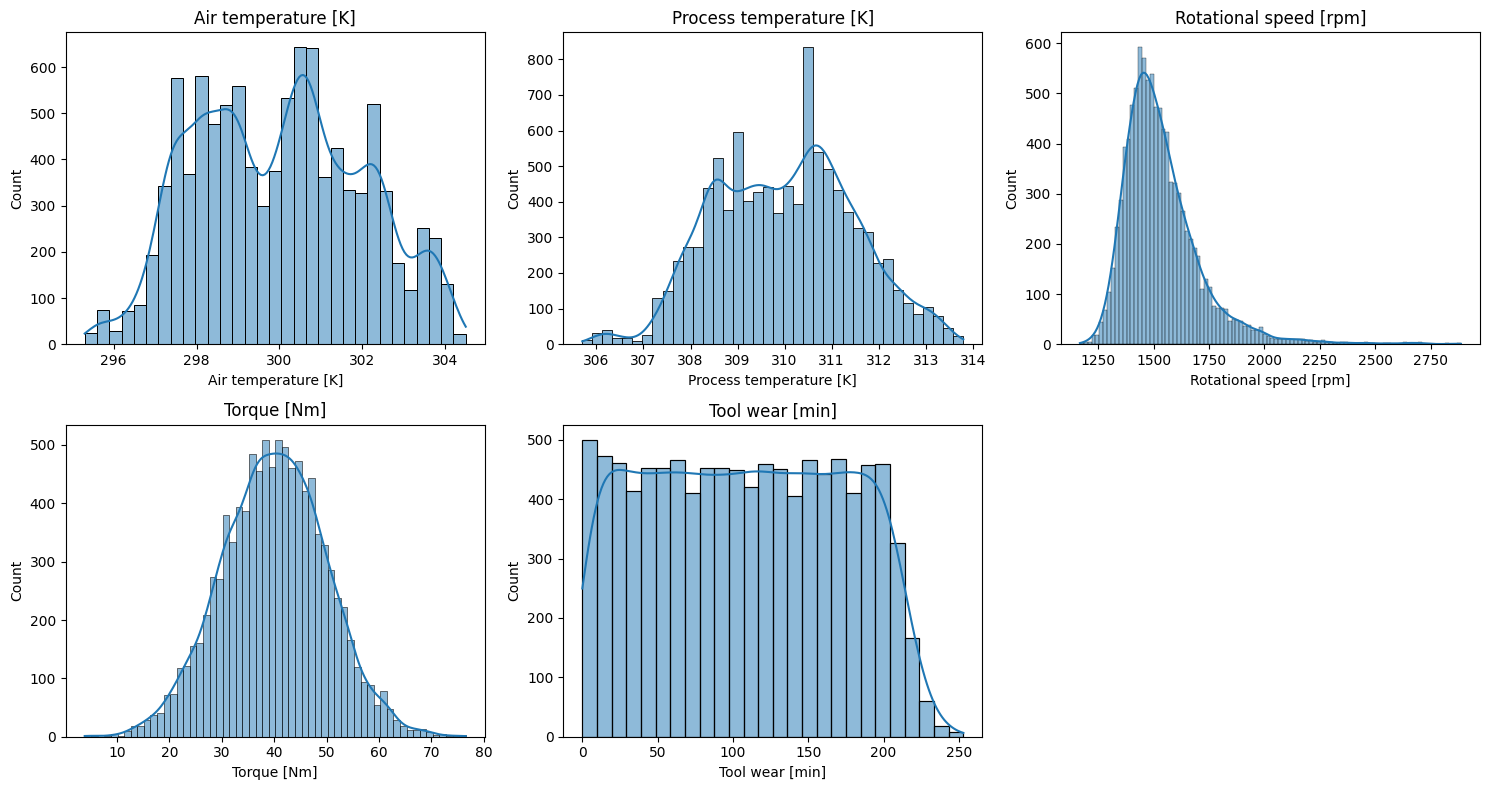

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
num_cols = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]",
            "Torque [Nm]", "Tool wear [min]"]
for ax, col in zip(axes.flat, num_cols):
    sns.histplot(df[col], kde=True, ax=ax)
    ax.set_title(col)
axes.flat[-1].axis("off")
plt.tight_layout()
plt.savefig("/content/eda_distributions.png", dpi=120)
plt.show()

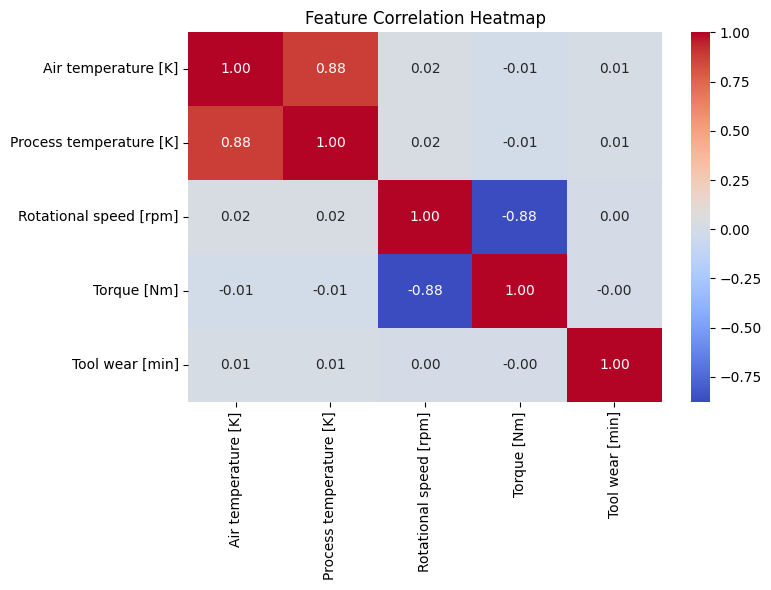

In [ ]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig("/content/correlation_heatmap.png", dpi=120)
plt.show()

## Step 3 — Preprocessing



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# No missing values expected in AI4I, but handle defensively
df = df.dropna()

TARGET = "Tool wear [min]"

feature_cols = ["Type", "Air temperature [K]", "Process temperature [K]",
                "Rotational speed [rpm]", "Torque [Nm]"]

X = df[feature_cols]
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

numeric_features = ["Air temperature [K]", "Process temperature [K]", "Rotational speed [rpm]", "Torque [Nm]"]
categorical_features = ["Type"]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("cat", OneHotEncoder(drop="first"), categorical_features),
])

print(f"Train size: {X_train.shape}, Test size: {X_test.shape}")

Train size: (8000, 5), Test size: (2000, 5)


## Step 4 — Model Implementation
**Linear, Polynomial, and Multivariate regression**.

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

results = {}

def evaluate_and_store(name, pipeline):
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, y_pred)
    results[name] = {"MSE": mse, "RMSE": rmse, "R2": r2}
    print(f"{name}: MSE={mse:.3f}, RMSE={rmse:.3f}, R2={r2:.4f}")
    return pipeline, y_pred

In [ ]:
linear_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression()),
])
linear_model, linear_pred = evaluate_and_store("Linear (Multivariate) Regression", linear_pipeline)

Linear (Multivariate) Regression: MSE=4275.302, RMSE=65.386, R2=-0.0014


In [ ]:
poly_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("poly", PolynomialFeatures(degree=2, include_bias=False)),
    ("regressor", LinearRegression()),
])
poly_model, poly_pred = evaluate_and_store("Polynomial Regression (deg=2)", poly_pipeline)

Polynomial Regression (deg=2): MSE=4273.002, RMSE=65.368, R2=-0.0009


In [ ]:
multivariate_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression()),
])
multivariate_model, multivariate_pred = evaluate_and_store("Multivariate Regression", multivariate_pipeline)

Multivariate Regression: MSE=4275.302, RMSE=65.386, R2=-0.0014


## Step 5 — Comparative Analysis
Task 4: compare performance, strengths/weaknesses, interpretability, complexity.


In [ ]:
results_df = pd.DataFrame(results).T
results_df = results_df.sort_values("R2", ascending=False)
print(results_df)

results_df.to_csv("/content/regression_comparison.csv")
print("\nSaved comparison table -> /content/regression_comparison.csv")

                                          MSE       RMSE        R2
Polynomial Regression (deg=2)     4273.002078  65.368204 -0.000863
Linear (Multivariate) Regression  4275.302012  65.385794 -0.001401
Multivariate Regression           4275.302012  65.385794 -0.001401

Saved comparison table -> /content/regression_comparison.csv


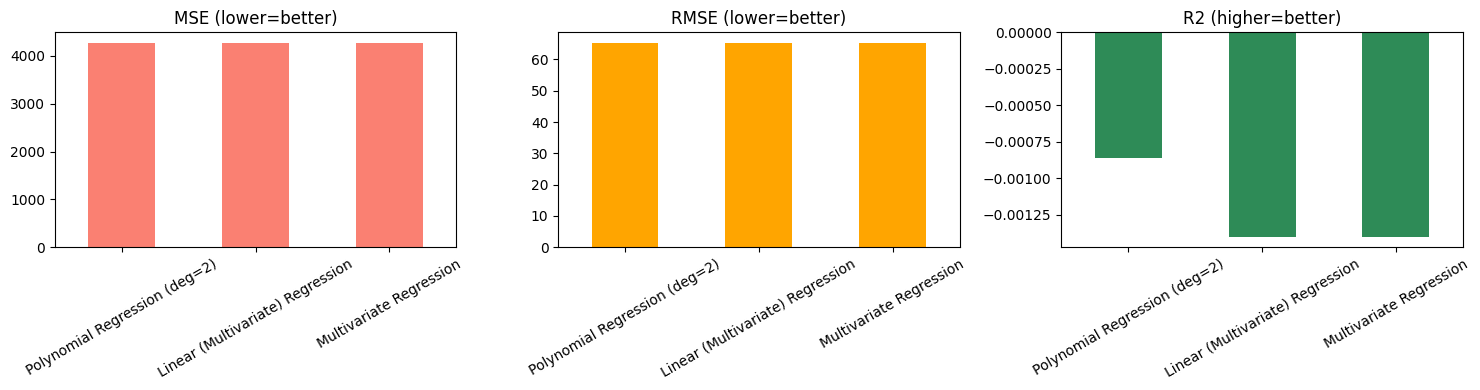

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
results_df["MSE"].plot(kind="bar", ax=axes[0], title="MSE (lower=better)", color="salmon")
results_df["RMSE"].plot(kind="bar", ax=axes[1], title="RMSE (lower=better)", color="orange")
results_df["R2"].plot(kind="bar", ax=axes[2], title="R2 (higher=better)", color="seagreen")
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig("/content/regression_comparison_chart.png", dpi=120)
plt.show()

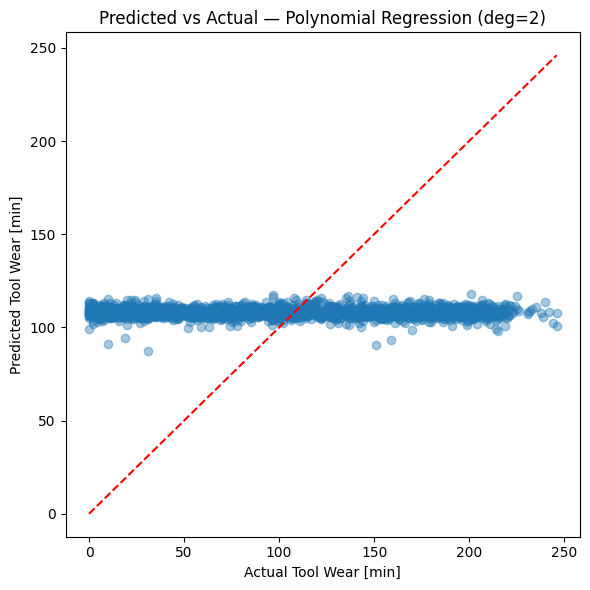

Best performing model: Polynomial Regression (deg=2)


In [ ]:
best_model_name = results_df.index[0]
best_pred = {"Linear (Multivariate) Regression": linear_pred,
             "Polynomial Regression (deg=2)": poly_pred,
             "Multivariate Regression": multivariate_pred}[best_model_name]

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_pred, alpha=0.4)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.xlabel("Actual Tool Wear [min]")
plt.ylabel("Predicted Tool Wear [min]")
plt.title(f"Predicted vs Actual — {best_model_name}")
plt.tight_layout()
plt.savefig("/content/predicted_vs_actual.png", dpi=120)
plt.show()

print(f"Best performing model: {best_model_name}")

## Step 6 — Conclusion (fill in after reviewing your results)


In [ ]:
for name, pipeline in [("Linear", linear_model), ("Polynomial", poly_model)]:
    train_r2 = r2_score(y_train, pipeline.predict(X_train))
    test_r2 = r2_score(y_test, pipeline.predict(X_test))
    print(f"{name}: Train R2={train_r2:.4f}, Test R2={test_r2:.4f}, Gap={train_r2-test_r2:.4f}")

Linear: Train R2=0.0002, Test R2=-0.0014, Gap=0.0016
Polynomial: Train R2=0.0017, Test R2=-0.0009, Gap=0.0026


In [ ]:
import joblib, os
os.makedirs("/content/models/regression", exist_ok=True)
joblib.dump(linear_model, "/content/models/regression/linear_regression.joblib")
joblib.dump(poly_model, "/content/models/regression/polynomial_regression.joblib")
print("Saved regression models to /content/models/regression/")

from google.colab import drive
drive.mount('/content/drive', force_remount=False)
!mkdir -p /content/drive/MyDrive/predictguard-ai/phase2_regression
!cp /content/models/regression/*.joblib /content/drive/MyDrive/predictguard-ai/phase2_regression/
!cp /content/*.png /content/regression_comparison.csv /content/drive/MyDrive/predictguard-ai/phase2_regression/ 2>/dev/null
print("Copied Phase 2 outputs to Drive: MyDrive/predictguard-ai/phase2_regression/")

Saved regression models to /content/models/regression/
Mounted at /content/drive
Copied Phase 2 outputs to Drive: MyDrive/predictguard-ai/phase2_regression/
